# NB 5/6 · POMDP — Partially Observable MDP

---
### References
[Ka] Kaelbling L.P. et al. (1998) Planning in POMDP. *Artif. Intell.* **101**  
[Li] Littman M. et al. (1995) QMDP approximation. *Proc. UAI-95*  
[M]  Mnih V. et al. (2015) Human-level control via DRL. *Nature* **518**

In [10]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.optim as optim
from shared_data import print_metrics
import warnings; warnings.filterwarnings('ignore')
np.random.seed(42); torch.manual_seed(42)
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,
                     'axes.spines.right':False,'font.size':11})
STAGE_NAMES=['W','N1','N2','N3','REM']; N_STAGES=5; N_ACTIONS=3
STAGE_COLORS={'W':'#4c78a8','N1':'#f58518','N2':'#54a24b',
              'N3':'#e45756','REM':'#b279a2'}
y_tr=np.load('y_tr.npy'); y_te=np.load('y_te.npy')
T=np.load('T.npy'); R_mdp=np.load('R_mdp.npy')
Q_star=np.load('Q_star.npy')
hmm_tr=np.load('hmm_tr.npy'); hmm_te=np.load('hmm_te.npy')
r_mdp_te=float(np.load('r_mdp_te.npy')[0])
print('POMDP artefacts loaded.')

POMDP artefacts loaded.


## §1 — Why POMDP?

The true sleep stage $z_t$ is **hidden** — the agent only observes the noisy HMM-decoded estimate $o_t\in\{W,N1,N2,N3,REM\}$. The full POMDP tuple [Ka]:

$$\bigl(\mathcal{S},\mathcal{A},\mathcal{O},P,Z,R,\gamma\bigr)$$

where $Z(o\mid s)=P(\text{HMM predicts }o\mid\text{true stage }s)$ is the observation model estimated from the HMM training confusion.

## §2 — Belief State [Ka]

$$b_t(s) = P(z_t=s\mid o_{1:t}, a_{1:t-1})$$

**Bayesian update** (predict → observe):
$$\tilde{b}_{t}(s') = (T^\top b_{t-1})(s')$$
$$b_t(s') = \frac{Z(o_t\mid s')\,\tilde{b}_t(s')}{\displaystyle\sum_{s''}Z(o_t\mid s'')\,\tilde{b}_t(s'')}$$

## §3 — Self-Adaptive POMDP: QMDP [Li]

QMDP assumes full observability after one step, giving a linear policy:
$$a^*_t = \arg\max_a \sum_s b_t(s)\,Q^*_{\text{MDP}}(s,a)$$

## §4 — Self-Adaptive Deep POMDP [M]

A neural network approximates $\hat{Q}(b_t,a;\theta)$ via TD(0):
$$\mathcal{L}(\theta)=\mathbb{E}\!\left[\Bigl(r_t+\gamma\max_{a'}\hat{Q}(b_{t+1},a';\theta^-)-\hat{Q}(b_t,a_t;\theta)\Bigr)^2\right]$$

**Training strategy:** we use **iterative online training** — in each round the current policy collects a new belief trajectory, then the network is updated. This is critical: collecting experience only once with a random initial policy and training offline would give a degenerate policy that never improves.

In [11]:
# Observation model Z — from HMM confusion on balanced training set
Z = np.zeros((N_STAGES, N_STAGES)) + 1e-6
for tr, pr in zip(y_tr, hmm_tr): Z[int(tr), int(pr)] += 1
Z /= Z.sum(1, keepdims=True)
print('Observation model Z  [P(hmm_pred | true_stage)]:')
print(pd.DataFrame(Z, index=STAGE_NAMES,
                   columns=[f'obs={s}' for s in STAGE_NAMES]).round(3).to_string())

Observation model Z  [P(hmm_pred | true_stage)]:
     obs=W  obs=N1  obs=N2  obs=N3  obs=REM
W    0.855   0.015   0.035   0.046    0.048
N1   0.269   0.199   0.094   0.013    0.426
N2   0.082   0.187   0.294   0.159    0.278
N3   0.081   0.055   0.038   0.738    0.088
REM  0.060   0.188   0.075   0.027    0.650


In [12]:
# QMDP self-adaptive POMDP
class BeliefPOMDP:
    def __init__(self, T, Q, Z):
        self.T, self.Q, self.Z = T, Q, Z
    def update(self, b, obs):
        bp = self.T.T @ b
        bn = bp * self.Z[:, obs]
        n  = bn.sum()
        return bn/n if n > 1e-12 else bp
    def act(self, b):
        return int((b @ self.Q).argmax())
    def run(self, y, hmm_obs, R):
        b = np.ones(N_STAGES) / N_STAGES; rew = 0.; bels = [b.copy()]
        for t in range(len(y)-1):
            a = self.act(b); rew += R[int(y[t]), a]
            b = self.update(b, int(hmm_obs[t]))
            bels.append(b.copy())
        return rew, np.array(bels)

pomdp = BeliefPOMDP(T, Q_star, Z)
pomdp_rew, bels = pomdp.run(y_te, hmm_te, R_mdp)
print(f'QMDP self-adaptive reward : {pomdp_rew:.1f}')
print(f'MDP oracle (full obs)     : {r_mdp_te:.1f}')
print(f'POMDP gap: {r_mdp_te-pomdp_rew:.1f}  '
      f'({(1-pomdp_rew/r_mdp_te)*100:.1f}% below oracle)')

QMDP self-adaptive reward : 7101.4
MDP oracle (full obs)     : 8415.4
POMDP gap: 1314.0  (15.6% below oracle)


In [13]:
# ── Deep POMDP with iterative online training ────────────────────────────
# Why iterative? If we collect belief trajectories with a random policy
# and train offline just once, the network never sees good-quality
# (b_t, a_t, r_t) tuples and converges to a trivial policy.
# Instead, we alternate: (1) collect trajectory with current policy,
# (2) update network, repeat N_ROUNDS times with decaying exploration.

class BeliefQNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(N_STAGES, 128), nn.ReLU(),
            nn.Linear(128, 64),       nn.ReLU(),
            nn.Linear(64, N_ACTIONS)
        )
    def forward(self, b): return self.net(b)

def train_deep_pomdp_online(y_tr, htr, R, T, Z, n_rounds=10, n_ep=500, lr=5e-4, gamma=0.95):
    net = BeliefQNet()
    net_target = BeliefQNet(); net_target.load_state_dict(net.state_dict())
    opt = optim.Adam(net.parameters(), lr=lr)
    loss_h, steps = [], 0; target_freq = 50  # ← UNCOMMENTED

    for rnd in range(n_rounds):
        eps = max(0.05, 0.8 - rnd * 0.15)
        Bs, As, Rs, Bns = [], [], [], []
        b = np.ones(N_STAGES) / N_STAGES
        for t in range(len(y_tr)-1):
            if np.random.rand() < eps: a = np.random.randint(N_ACTIONS)
            else:
                with torch.no_grad(): a = int(net(torch.FloatTensor(b)).argmax())
            Bs.append(b.copy()); As.append(a)
            Rs.append(float(R[int(y_tr[t]), a]))
            bp = T.T @ b; b = bp * Z[:, int(htr[t])]; b /= max(b.sum(), 1e-12)
            Bns.append(b.copy())

        bt  = torch.FloatTensor(Bs); at = torch.LongTensor(As)
        bnt = torch.FloatTensor(Bns); rt = torch.FloatTensor(Rs)

        for _ in range(n_ep):
            idx = np.random.randint(0, len(Rs), 128)
            with torch.no_grad():
                a_star = net(bnt[idx]).argmax(dim=1, keepdim=True)
                tgt = rt[idx] + gamma * net_target(bnt[idx]).gather(1, a_star).squeeze()
            q_pred = net(bt[idx]).gather(1, at[idx].unsqueeze(1)).squeeze()
            loss = nn.HuberLoss()(q_pred, tgt)  # ← entropy removed (see note below)
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step(); steps += 1
            if steps % target_freq == 0:
                for p_t, p in zip(net_target.parameters(), net.parameters()):
                    p_t.data.copy_(0.005*p.data + 0.995*p_t.data)
            loss_h.append(loss.item())
        print(f'  Round {rnd+1}/{n_rounds}: eps={eps:.2f}  avg_reward={np.mean(Rs):.3f}')
    return net, loss_h
    
print('Training Deep POMDP (10 rounds x 500 mini-batch steps)...')
deep_net, dp_loss = train_deep_pomdp_online(y_tr, hmm_tr, R_mdp, T, Z)
# Evaluate with greedy policy (no exploration)
b = np.ones(N_STAGES)/N_STAGES; dp_rew = 0.
for t in range(len(y_te)-1):
    a = int(deep_net(torch.FloatTensor(b)).argmax())
    dp_rew += R_mdp[int(y_te[t]), a]
    bp = T.T @ b
    b  = bp * Z[:, int(hmm_te[t])]; b /= max(b.sum(), 1e-12)
print(f'Deep POMDP reward  : {dp_rew:.1f}')
print(f'QMDP reward        : {pomdp_rew:.1f}')
print(f'MDP oracle         : {r_mdp_te:.1f}')

Training Deep POMDP (10 rounds x 500 mini-batch steps)...
  Round 1/10: eps=0.80  avg_reward=0.605
  Round 2/10: eps=0.65  avg_reward=0.640
  Round 3/10: eps=0.50  avg_reward=0.651
  Round 4/10: eps=0.35  avg_reward=0.663
  Round 5/10: eps=0.20  avg_reward=0.673
  Round 6/10: eps=0.05  avg_reward=0.685
  Round 7/10: eps=0.05  avg_reward=0.684
  Round 8/10: eps=0.05  avg_reward=0.686
  Round 9/10: eps=0.05  avg_reward=0.685
  Round 10/10: eps=0.05  avg_reward=0.686
Deep POMDP reward  : 6917.4
QMDP reward        : 7101.4
MDP oracle         : 8415.4


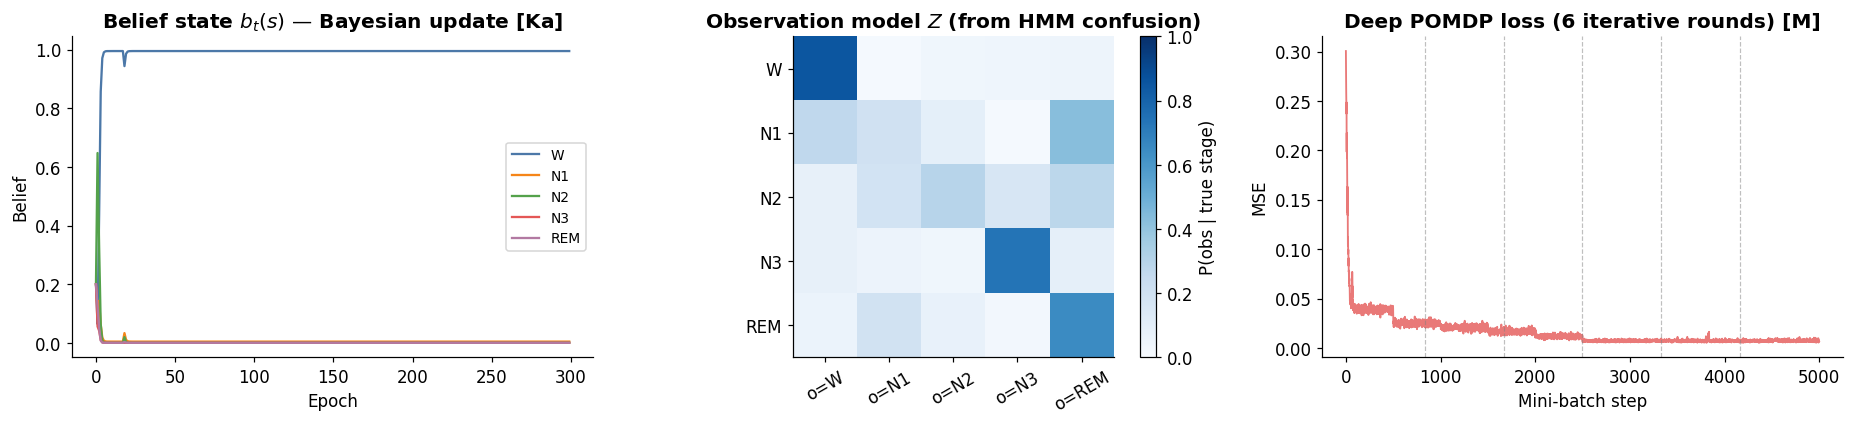

6917.400000000163
POMDP artefacts saved.


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
# belief state over time
t_s = min(300, len(bels))
for i, s in enumerate(STAGE_NAMES):
    axes[0].plot(bels[:t_s,i], label=s,
                  color=list(STAGE_COLORS.values())[i], lw=1.5)
axes[0].set_title('Belief state $b_t(s)$ — Bayesian update [Ka]', fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Belief'); axes[0].legend(fontsize=9)
# observation model Z
im = axes[1].imshow(Z, cmap='Blues', vmin=0, vmax=1)
plt.colorbar(im, ax=axes[1], label='P(obs | true stage)')
axes[1].set_xticks(range(N_STAGES))
axes[1].set_xticklabels([f'o={s}' for s in STAGE_NAMES], rotation=30)
axes[1].set_yticks(range(N_STAGES)); axes[1].set_yticklabels(STAGE_NAMES)
axes[1].set_title('Observation model $Z$ (from HMM confusion)', fontweight='bold')
# deep POMDP training loss
dp_arr = np.array(dp_loss)
axes[2].plot(dp_arr, color='#e45756', lw=1.2, alpha=0.8)
# mark round boundaries
step = len(dp_arr) // 6
for rnd in range(1, 6):
    axes[2].axvline(rnd*step, color='gray', ls='--', lw=0.8, alpha=0.5)
axes[2].set_title('Deep POMDP loss (6 iterative rounds) [M]', fontweight='bold')
axes[2].set_xlabel('Mini-batch step'); axes[2].set_ylabel('MSE')
plt.tight_layout()
plt.savefig('fig8_pomdp.png', bbox_inches='tight'); plt.show()

np.save('pomdp_rew.npy', np.array([pomdp_rew]))
np.save('dp_rew.npy',    np.array([dp_rew]))
print('POMDP artefacts saved.')